# Consumer Complaints Analysis
This notebook analyzes consumer finance complaints data to predict dispute likelihood.

In [ ]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, learning_curve
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
import seaborn as sns
sns.set_theme()
import warnings
warnings.filterwarnings('ignore')

# Set style for better visualizations
plt.style.use('default')
sns.set_palette('husl')
%matplotlib inline

## 1. Data Loading

In [ ]:
# Load the data
path = kagglehub.dataset_download("kaggle/us-consumer-finance-complaints")
file_path = os.path.join(path, "consumer_complaints.csv")
data = pd.read_csv(file_path, dtype=str)
data = data.head(5000)  # Using first 5000 rows for analysis

print("Data shape:", data.shape)
print("Columns:", data.columns.tolist())
print("Sample of data:")
display(data.head())

print("Data info:")
data.info()

Data shape: (5000, 18)
Columns: ['date_received', 'product', 'sub_product', 'issue', 'sub_issue', 'consumer_complaint_narrative', 'company_public_response', 'company', 'state', 'zipcode', 'tags', 'consumer_consent_provided', 'submitted_via', 'date_sent_to_company', 'company_response_to_consumer', 'timely_response', 'consumer_disputed?', 'complaint_id']
Sample of data:


,date_received,product,sub_product,issue,sub_issue,consumer_complaint_narrative,company_public_response,company,state,zipcode,tags,consumer_consent_provided,submitted_via,date_sent_to_company,company_response_to_consumer,timely_response,consumer_disputed?,complaint_id
0,08/30/2013,Mortgage,Other mortgage,"Loan modification,collection,foreclosure",NaN,NaN,NaN,U.S. Bancorp,CA,95993,NaN,NaN,Referral,09/03/2013,Closed with explanation,Yes,Yes,511074
1,08/30/2013,Mortgage,Other mortgage,"Loan servicing, payments, escrow account",NaN,NaN,NaN,Wells Fargo & Company,CA,91104,NaN,NaN,Referral,09/03/2013,Closed with explanation,Yes,Yes,511080
2,08/30/2013,Credit reporting,NaN,Incorrect information on credit report,Account status,NaN,NaN,Wells Fargo & Company,NY,11764,NaN,NaN,Postal mail,09/18/2013,Closed with explanation,Yes,No,510473
3,08/30/2013,Student loan,Non-federal student loan,Repaying your loan,Repaying your loan,NaN,NaN,"Navient Solutions, Inc.",MD,21402,NaN,NaN,Email,08/30/2013,Closed with explanation,Yes,Yes,510326
4,08/30/2013,Debt collection,Credit card,False statements or representation,Attempted to collect wrong amount,NaN,NaN,Resurgent Capital Services L.P.,GA,30106,NaN,NaN,Web,08/30/2013,Closed with explanation,Yes,Yes,511067


Data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   date_received                 5000 non-null   object
 1   product                       5000 non-null   object
 2   sub_product                   3769 non-null   object
 3   issue                         5000 non-null   object
 4   sub_issue                     1780 non-null   object
 5   consumer_complaint_narrative  0 non-null      object
 6   company_public_response       0 non-null      object
 7   company                       5000 non-null   object
 8   state                         4988 non-null   object
 9   zipcode                       4988 non-null   object
 10  tags                          680 non-null    object
 11  consumer_consent_provided     0 non-null      object
 12  submitted_via                 5000 non-null   object
 13  date_se

## 2. Data Cleaning and Preprocessing

In [ ]:
# Select important columns
cols_to_keep = [
    'date_received', 'product', 'sub_product', 'issue', 'sub_issue',
    'consumer_complaint_narrative', 'company_public_response', 'company',
    'state', 'zipcode', 'tags', 'consumer_consent_provided', 'submitted_via',
    'date_sent_to_company', 'company_response_to_consumer',
    'timely_response', 'consumer_disputed?', 'complaint_id'
]
data = data[cols_to_keep]

# Handle missing values
print("Missing values before cleaning:")
print(data.isnull().sum())

data = data.dropna(subset=['consumer_disputed?'])
data.fillna('Unknown', inplace=True)

print("Missing values after cleaning:")
print(data.isnull().sum())

Missing values before cleaning:
date_received                      0
product                            0
sub_product                     1231
issue                              0
sub_issue                       3220
consumer_complaint_narrative    5000
company_public_response         5000
company                            0
state                             12
zipcode                           12
tags                            4320
consumer_consent_provided       5000
submitted_via                      0
date_sent_to_company               0
company_response_to_consumer       0
timely_response                    0
consumer_disputed?                 0
complaint_id                       0
dtype: int64
Missing values after cleaning:
date_received                   0
product                         0
sub_product                     0
issue                           0
sub_issue                       0
consumer_complaint_narrative    0
company_public_response         0
company             

In [ ]:
# Convert dates and calculate response time
data['date_received'] = pd.to_datetime(data['date_received'])
data['date_sent_to_company'] = pd.to_datetime(data['date_sent_to_company'])
data['response_time'] = (data['date_sent_to_company'] - data['date_received']).dt.days

# Group ZIP codes by region
data['zipcode_region'] = data['zipcode'].apply(lambda x: str(x)[:2] if x != 'Unknown' and not pd.isna(x) else 'Unknown')
data = data.drop(columns=['zipcode'])

# Convert target to binary
data['consumer_disputed?'] = data['consumer_disputed?'].apply(lambda x: 1 if x == 'Yes' else 0)

# Feature engineering
data['complain_length'] = data['consumer_complaint_narrative'].apply(lambda x: len(str(x).split()))
data['has_narrative'] = data['consumer_complaint_narrative'].apply(lambda x: 0 if x == 'Unknown' else 1)
data['n_unique_words'] = data['consumer_complaint_narrative'].apply(lambda x: len(set(str(x).split())))
data['char_length'] = data['consumer_complaint_narrative'].apply(lambda x: len(str(x)))

print("Engineered features statistics:")
print(data[['complain_length', 'n_unique_words', 'char_length', 'response_time']].describe())

Engineered features statistics:
       complain_length  n_unique_words  char_length  response_time
count           5000.0          5000.0       5000.0     5000.00000
mean               1.0             1.0          7.0        4.18220
std                0.0             0.0          0.0       16.44474
min                1.0             1.0          7.0       -1.00000
25%                1.0             1.0          7.0        0.00000
50%                1.0             1.0          7.0        1.00000
75%                1.0             1.0          7.0        2.00000
max                1.0             1.0          7.0      540.00000


## 3. Exploratory Data Analysis

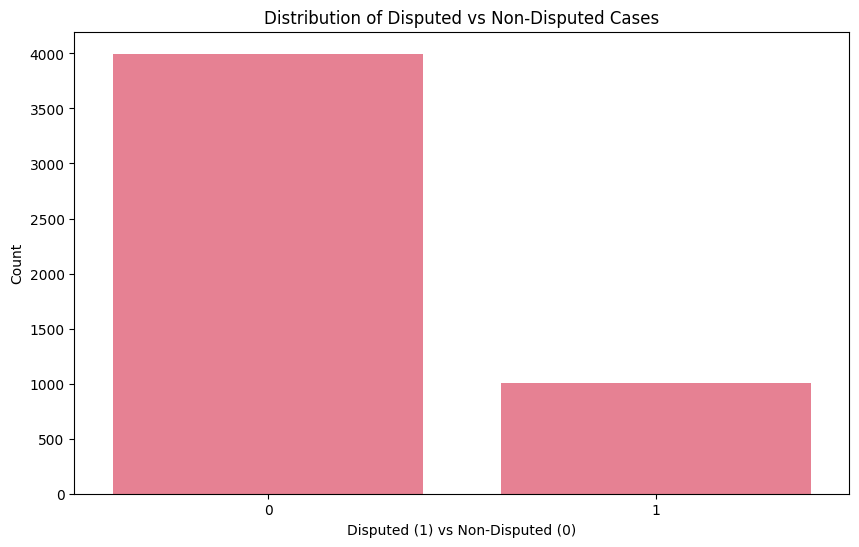

Class distribution:
consumer_disputed?
0    0.7994
1    0.2006
Name: proportion, dtype: float64


In [ ]:
# 1. Class Distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='consumer_disputed?')
plt.title('Distribution of Disputed vs Non-Disputed Cases')
plt.xlabel('Disputed (1) vs Non-Disputed (0)')
plt.ylabel('Count')
plt.show()

print("Class distribution:")
print(data['consumer_disputed?'].value_counts(normalize=True))

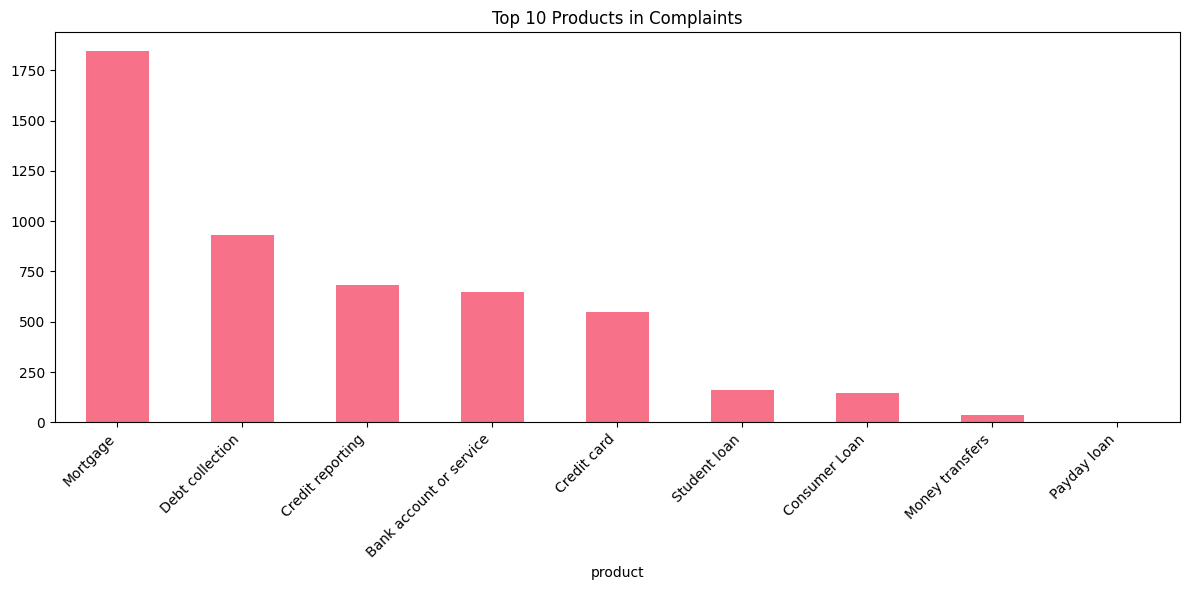

In [ ]:
# 2. Product Distribution
plt.figure(figsize=(12, 6))
data['product'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Products in Complaints')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

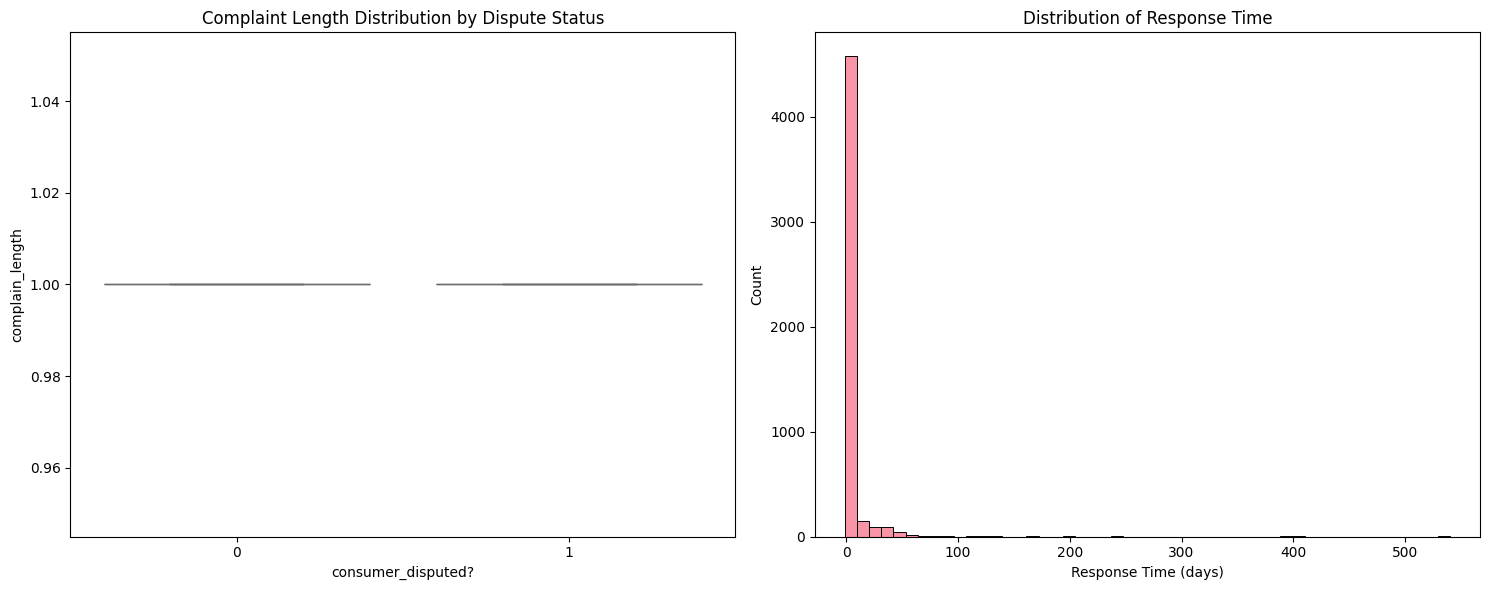

In [ ]:
# 3. Complaint Length Analysis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(data=data, x='consumer_disputed?', y='complain_length', ax=ax1)
ax1.set_title('Complaint Length Distribution by Dispute Status')

sns.histplot(data=data, x='response_time', bins=50, ax=ax2)
ax2.set_title('Distribution of Response Time')
ax2.set_xlabel('Response Time (days)')

plt.tight_layout()
plt.show()

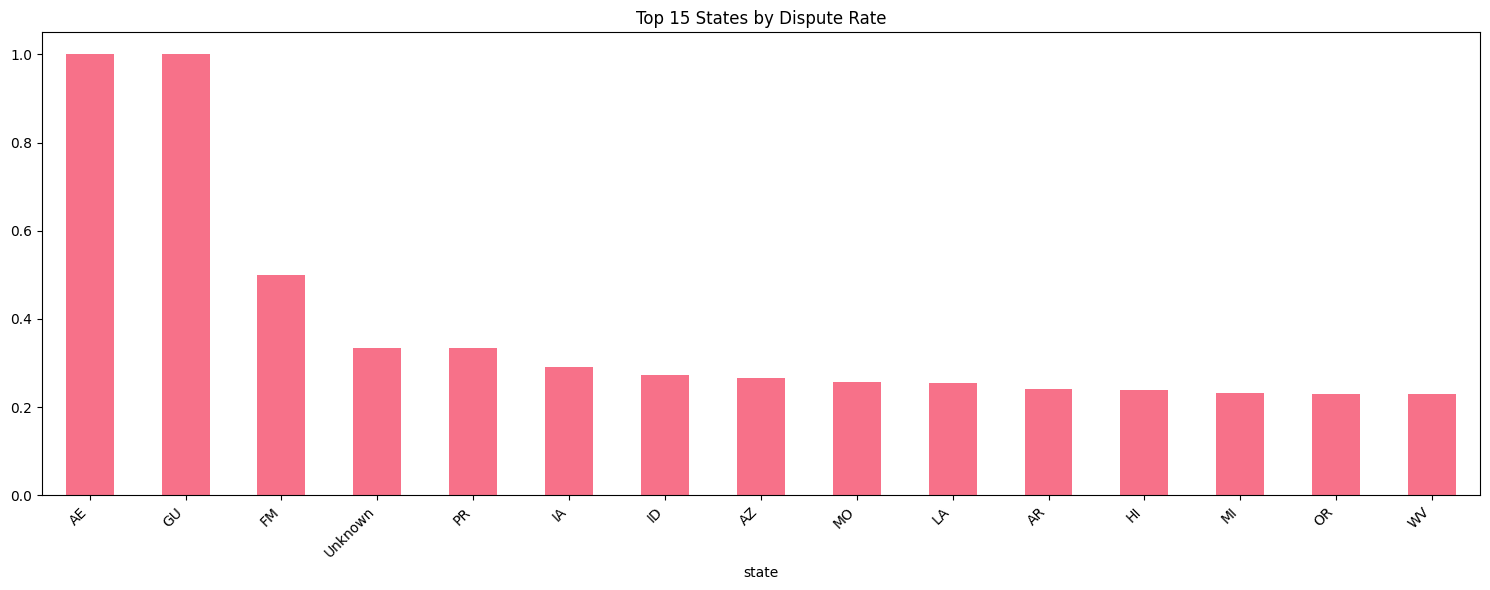

In [ ]:
# 4. State-wise Analysis
state_dispute_rate = data.groupby('state')['consumer_disputed?'].mean().sort_values(ascending=False)

plt.figure(figsize=(15, 6))
state_dispute_rate.head(15).plot(kind='bar')
plt.title('Top 15 States by Dispute Rate')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 4. Feature Preparation

In [ ]:
# Identify categorical features
categorical_features = data.select_dtypes(include=['object']).columns.tolist()
categorical_features = [c for c in categorical_features if c != 'complaint_id']

# Initialize encoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Encode categorical features
encoded_categorical = encoder.fit_transform(data[categorical_features])
encoded_categorical = pd.DataFrame(
    encoded_categorical,
    columns=encoder.get_feature_names_out(categorical_features)
)

# Combine features
numerical_features = ['complain_length', 'n_unique_words', 'char_length', 'response_time']
X = pd.concat([
    data[numerical_features],
    encoded_categorical
], axis=1)

y = data['consumer_disputed?']

print(f"Features prepared! Total features: {X.shape[1]}")

Features prepared! Total features: 820


## 5. Model Training and Evaluation

In [ ]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=11, stratify=y
)

# Apply SMOTE
smote = SMOTE(random_state=11)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# Define models
models = {
    "Random Forest": RandomForestClassifier(random_state=11),
    "Gradient Boosting": GradientBoostingClassifier(random_state=11),
    "KNN": Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier())
    ])
}

Training Random Forest...
Random Forest Performance Metrics:
Accuracy: 0.7850
Precision: 0.3333
Recall: 0.0697
AUC-ROC: 0.5499


<Figure size 800x600 with 0 Axes>

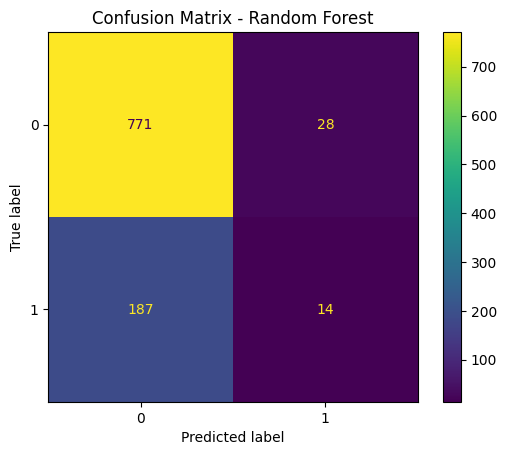

<Figure size 800x600 with 0 Axes>

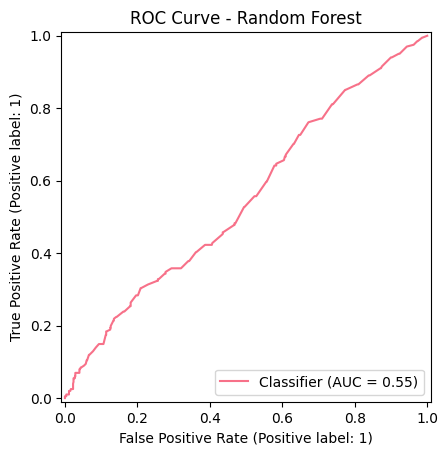

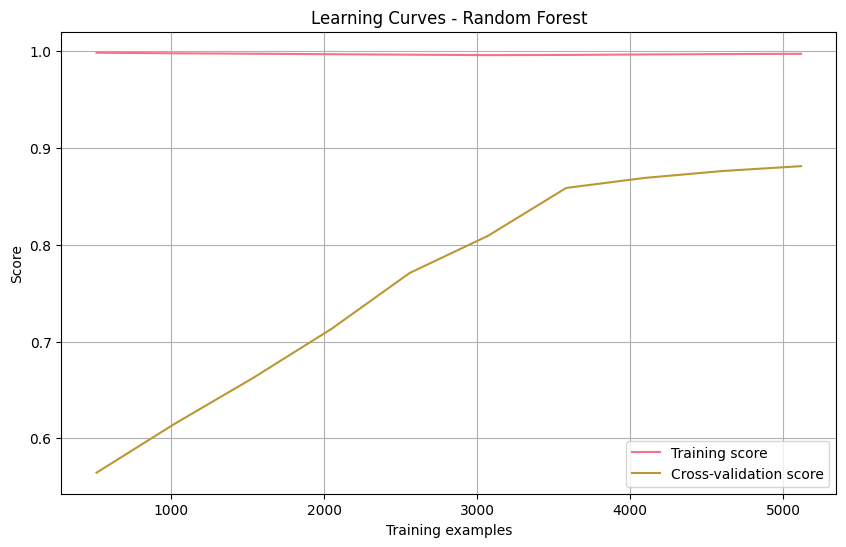

Training Gradient Boosting...
Gradient Boosting Performance Metrics:
Accuracy: 0.7500
Precision: 0.2752
Recall: 0.1493
AUC-ROC: 0.5592


<Figure size 800x600 with 0 Axes>

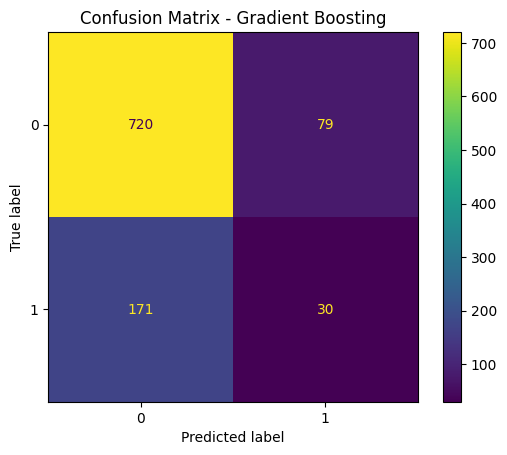

<Figure size 800x600 with 0 Axes>

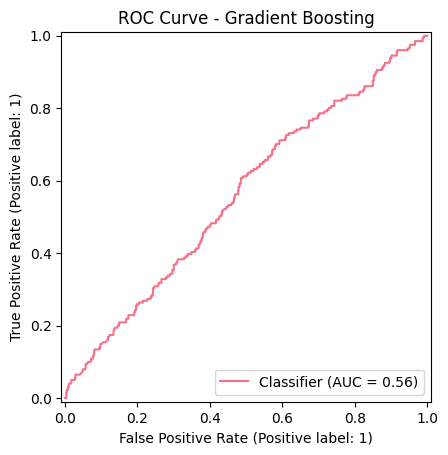

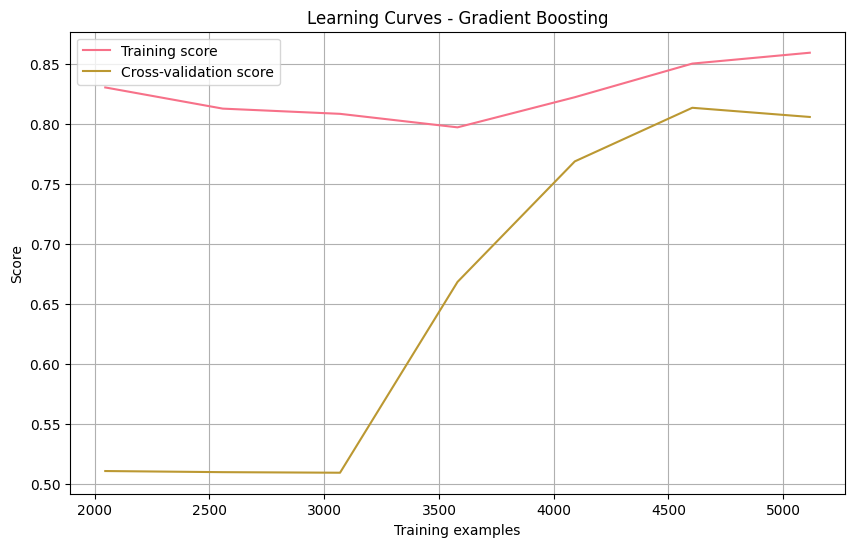

Training KNN...
KNN Performance Metrics:
Accuracy: 0.5950
Precision: 0.2167
Recall: 0.3881
AUC-ROC: 0.5372


<Figure size 800x600 with 0 Axes>

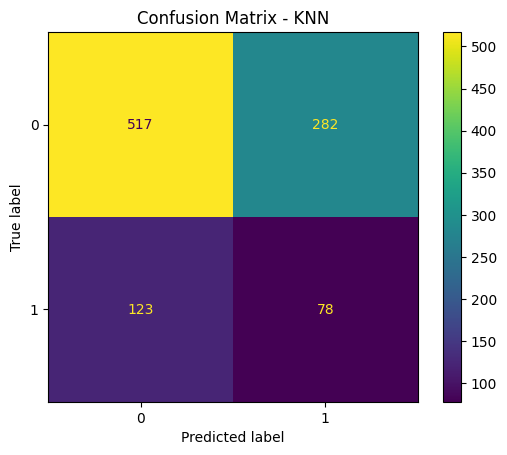

<Figure size 800x600 with 0 Axes>

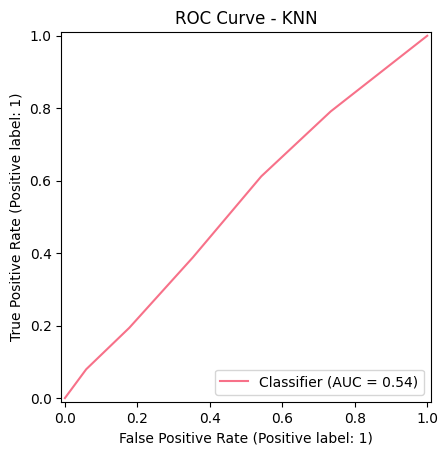

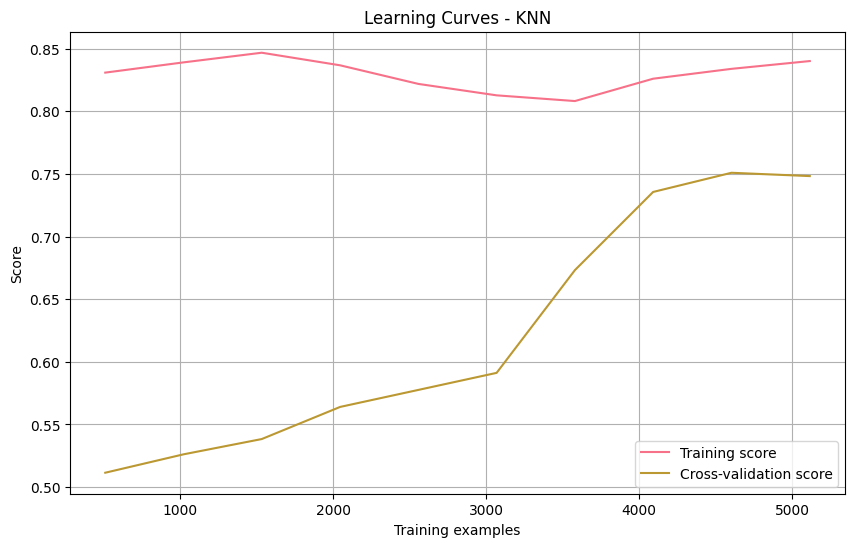

In [ ]:
# Train and evaluate models
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_res, y_train_res)

    # Make predictions
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    # Calculate metrics
    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'AUC-ROC': roc_auc_score(y_test, y_proba)
    }

    print(f"{name} Performance Metrics:")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

    # Plot confusion matrix
    plt.figure(figsize=(8, 6))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

    # Plot ROC curve
    plt.figure(figsize=(8, 6))
    RocCurveDisplay.from_predictions(y_test, y_proba)
    plt.title(f'ROC Curve - {name}')
    plt.show()

    # Plot learning curves
    train_sizes, train_scores, test_scores = learning_curve(
        model, X_train_res, y_train_res,
        cv=5, n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 10)
    )

    plt.figure(figsize=(10, 6))
    plt.plot(train_sizes, np.mean(train_scores, axis=1), label='Training score')
    plt.plot(train_sizes, np.mean(test_scores, axis=1), label='Cross-validation score')
    plt.xlabel('Training examples')
    plt.ylabel('Score')
    plt.title(f'Learning Curves - {name}')
    plt.legend(loc='best')
    plt.grid(True)
    plt.show()